In [1]:
import numpy as np

def plot_bin_matrix_heatmap(matrix_file_path, bin_length):
    with open(matrix_file_path, 'r') as f:
        matrix = [list(map(float, line.strip().split())) for line in f if line.strip()]
    
    matrix = np.array(matrix)
    num_bins_y, num_bins_x = matrix.shape
    
    fig, ax = plt.subplots(figsize=(8, 8))
    heatmap = ax.imshow(matrix, cmap='viridis', origin='lower', extent=[0, num_bins_x * bin_length, 0, num_bins_y * bin_length])

    # Add numbers to each bin
    for i in range(num_bins_y):
        for j in range(num_bins_x):
            x = (j + 0.5) * bin_length
            y = (i + 0.5) * bin_length
            value = matrix[i, j]
            ax.text(x, y, f'{value:.1f}', ha='center', va='center', color='white' if value > np.max(matrix)/2 else 'black', fontsize=10)

    ax.set_xticks(np.arange(0, num_bins_x * bin_length + 1, bin_length))
    ax.set_yticks(np.arange(0, num_bins_y * bin_length + 1, bin_length))
    ax.grid(True, which='both', color='gray', linestyle='--', linewidth=0.5)
    ax.set_title("Bin Matrix Heatmap")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

    plt.colorbar(heatmap, ax=ax, label='Value')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import math

def parse_and_plot_graph(file_path, show_slots=False):
    with open(file_path+".txt", 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    
    # Parse metadata
    header = lines[0].split()
    number_of_binsx = int(header[0])
    number_of_binsy = int(header[1])
    number_of_slots_per_bin = int(math.sqrt(int(header[2])))
    bin_length = float(header[3])
    
    # Parse inputs and outputs
    inputs = list(map(int, lines[1].split()[:]))
    print(inputs)
    outputs = list(map(int, lines[2].split()[:]))
    print(outputs)

    # Parse node data
    nodes = {}
    radii = {}
    edges = []
    for line in lines[3:]:
        parts = line.split()
        node = int(parts[0])
        radius = float(parts[1])
        x, y = float(parts[2]), float(parts[3])
        children = list(map(int, parts[4:]))
        nodes[node] = (x, y)
        radii[node] = radius
        for child in children:
            edges.append((child, node))  # directed from child to current node

    # Create graph
    G = nx.DiGraph()
    for node, pos in nodes.items():
        G.add_node(node, pos=pos)
    G.add_edges_from(edges)

    # Plotting
    plt.figure(figsize=(10, 10))
    pos = nx.get_node_attributes(G, 'pos')

    # Draw edges
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15)

    # Draw nodes manually as circles with radii
    ax = plt.gca()
    for node, (x, y) in nodes.items():
        radius = radii[node]
        color = 'skyblue'
        if node in inputs:
            color = 'lightgreen'
        elif node in outputs:
            color = 'salmon'
        circle = plt.Circle((x, y), radius, color=color, alpha=0.6, ec='black')
        ax.add_patch(circle)
        plt.text(x, y, str(node), fontsize=8, ha='center', va='center')

    # Draw bin and slot grid
    max_coordx = ( number_of_binsx ) * bin_length
    max_coordy = ( number_of_binsy ) * bin_length
    for i in range(number_of_binsx + 1):
        x = i * bin_length
        plt.plot([x, x], [0, max_coordy], 'k--', linewidth=0.5)

        if show_slots:
            slot_size = bin_length / number_of_slots_per_bin
            for j in range(1, number_of_slots_per_bin):
                x_inner = i * bin_length + j * slot_size
                if x_inner < max_coordx:
                    plt.plot([x_inner, x_inner], [0, max_coordy], 'k:', linewidth=0.3)

    for i in range(number_of_binsy + 1):
        y = i * bin_length
        plt.plot([0, max_coordx], [y, y], 'k--', linewidth=0.5)

        if show_slots:
            slot_size = bin_length / number_of_slots_per_bin
            for j in range(1, number_of_slots_per_bin):
                y_inner = i * bin_length + j * slot_size
                if y_inner < max_coordy:
                    plt.plot([0, max_coordx], [y_inner, y_inner], 'k:', linewidth=0.3)

    plt.xlim(-1, max_coordx + 1)
    plt.ylim(-1, max_coordy + 1)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title("Graph Visualization with Node Radii")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.show()

    #plot_bin_matrix_heatmap( file_path + "_matrix.txt", bin_length )
    

- Disk symmetry simplifies geometry and avoids biasing toward axes (as in rectangular grids).

- I/O fixed on perimeter models realistic boundary pin constraints.

- Spreading constraint enforces realistic density without overlap, reflecting placement feasibility.

- Delay proxy based on wirelength² gives a good approximation to post-routing interconnect delay in absence of parasitic extraction.

- Early feedback loop: You can optimize logic or mapping decisions using this geometric proxy before layout.

[2, 3, 4, 5]
[11, 13, 14]


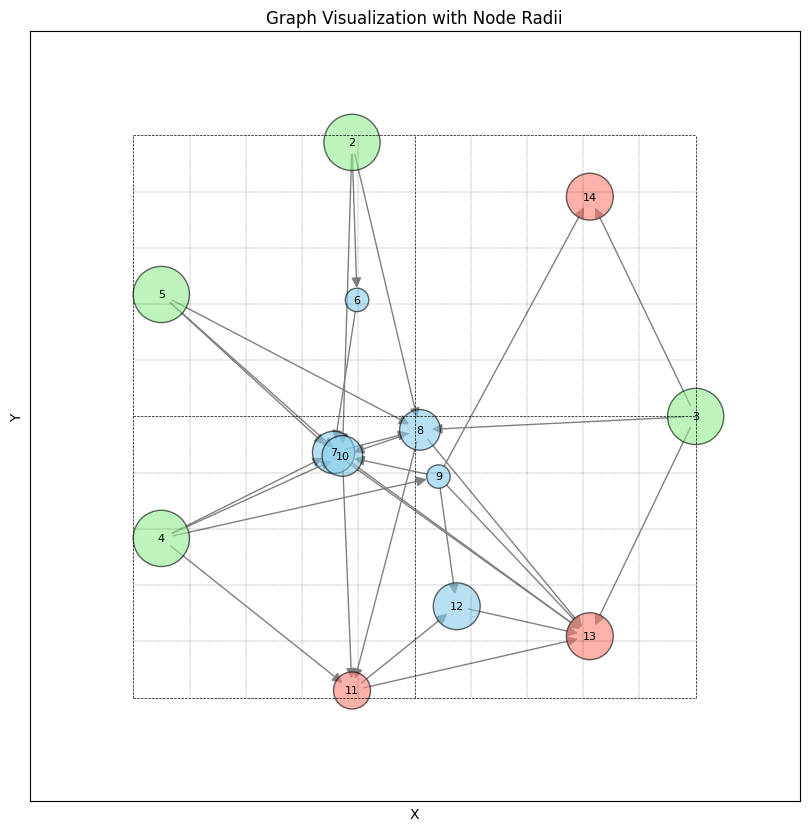

In [3]:
parse_and_plot_graph( "tmp0", True )

[2, 3, 4, 5]
[11, 15, 14]


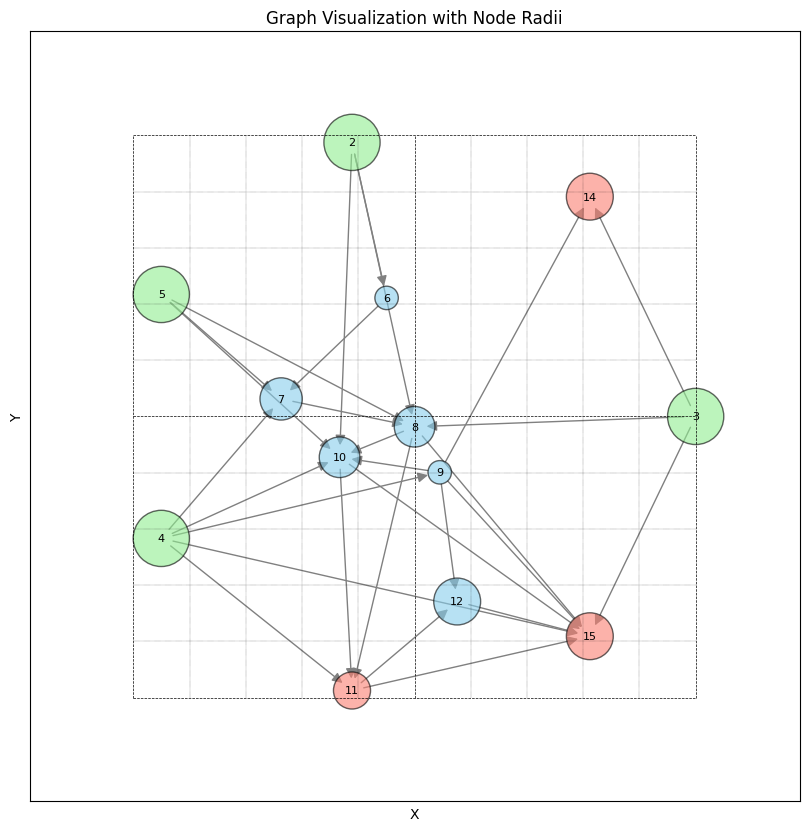

In [4]:
parse_and_plot_graph( "tmp1", True )

In [9]:
U0=[     1701.43,   121395.41,   286205.03,   670674.25,   231395.16,   254333.52,  3423690.00,  1288603.12, 15907557.00,  2855165.00, 24295474.00]
U1=[1701.43,110172.33,255285.92,618021.25,198212.95,217566.86,2794134.25,1154643.88,13064761.00,2799074.50,16890774.00]
W0=[32.46,1172.49,2021.79,3147.90,1957.03,1930.59,8808.44,6918.81,26696.22,12735.60,34350.29]
W1=[32.46,1164.14,2064.81,3195.59,1955.75,1791.24,8227.04,6782.59,23561.85,13205.69,28635.18]

In [10]:
dU=[ 100*(U1[i]-U0[i])/U0[i] for i in range(len(U0)) ]
dW=[ 100*(W1[i]-W0[i])/W0[i] for i in range(len(W0)) ]

In [11]:
import numpy as np

In [12]:
np.mean(dW)

-3.4190503703535033

In [13]:
np.mean(dU)

-12.344723448843723